# 01: Multi-Metal Electrochemical Database Exploration, Harmonization & Lookup

This notebook demonstrates the Phase 1 data ingestion, schema harmonization, reference electrode conversion ($\text{V vs. SHE}$), unit normalization ($\mu\text{A/cm}^2$ and positive $\text{mV/dec}$), missing Tafel slope imputation, per-solution **Galvanic Series** ranking, data dictionary generation, and nearest-neighbor **Exposure Condition** lookup covering the eight core semiconductor metals (`Cu`, `Co`, `W`, `Ru`, `Ti`, `Ta`, `Al`, `Mo`).

## 1. Raw Dataset Inspection & Harmonized Ingestion

We ingest the raw tables from `data/raw/` (supplemented with seed benchmarks so all eight core semiconductor metals are covered) into a unified `HarmonizedDatabase` and persist the processed tables to `data/processed/`.

In [1]:
from pathlib import Path
import sys

ROOT_DIR = Path.cwd().resolve()
if not (ROOT_DIR / "corrosion_simulator").exists() and (ROOT_DIR.parent / "corrosion_simulator").exists():
    ROOT_DIR = ROOT_DIR.parent
if str(ROOT_DIR) not in sys.path:
    sys.path.insert(0, str(ROOT_DIR))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from corrosion_simulator import (
    CORE_METALS,
    HarmonizedDatabase,
    convert_potential_to_she,
    normalize_current_density_to_uA_cm2,
    normalize_tafel_slope_to_mV_dec,
)

db = HarmonizedDatabase.from_directory(ROOT_DIR / "data" / "raw")
exported_paths = db.export_to_directory(ROOT_DIR / "data" / "processed")

summary_counts = pd.DataFrame(
    [
        {"Table": "electrochemical_database", "Rows": len(db.electrochemical_database), "Columns": db.electrochemical_database.shape[1]},
        {"Table": "material_properties", "Rows": len(db.material_properties), "Columns": db.material_properties.shape[1]},
        {"Table": "solution_properties", "Rows": len(db.solution_properties), "Columns": db.solution_properties.shape[1]},
        {"Table": "galvanic_series", "Rows": len(db.galvanic_series), "Columns": db.galvanic_series.shape[1]},
        {"Table": "data_dictionary", "Rows": len(db.data_dictionary), "Columns": db.data_dictionary.shape[1]},
    ]
)
print(summary_counts.to_string(index=False))

                   Table  Rows  Columns
electrochemical_database   180      120
     material_properties     8       24
     solution_properties   149       37
         galvanic_series    71       15
         data_dictionary   196        7


## 2. Reference Electrode & Unit Normalization Verification

All **Corrosion Potential ($E_{\text{corr}}$)** values are converted to $\text{V vs. SHE}$, all **Corrosion Current Density ($i_{\text{corr}}$)** values to $\mu\text{A/cm}^2$, and all anodic and cathodic **Tafel Slopes ($\beta_a, \beta_c$)** to strictly positive $\text{mV/dec}$.

In [2]:
conversion_examples = pd.DataFrame(
    [
        {"Reference": "SHE", "Input_Potential": 0.150, "Unit": "V", "pH": 7.0, "Ecorr_V_SHE": convert_potential_to_she(0.150, "SHE")},
        {"Reference": "Ag/AgCl", "Input_Potential": 0.379, "Unit": "V", "pH": 7.0, "Ecorr_V_SHE": convert_potential_to_she(0.379, "Ag/AgCl")},
        {"Reference": "SCE", "Input_Potential": 0.001, "Unit": "V", "pH": 7.0, "Ecorr_V_SHE": convert_potential_to_she(0.001, "SCE")},
        {"Reference": "MSE", "Input_Potential": -0.500, "Unit": "V", "pH": 7.0, "Ecorr_V_SHE": convert_potential_to_she(-0.500, "MSE")},
        {"Reference": "RHE", "Input_Potential": 0.800, "Unit": "V", "pH": 10.0, "Ecorr_V_SHE": convert_potential_to_she(0.800, "RHE", pH=10.0)},
    ]
)
print(conversion_examples.to_string(index=False))

Reference  Input_Potential Unit   pH  Ecorr_V_SHE
      SHE            0.150    V  7.0       0.1500
  Ag/AgCl            0.379    V  7.0       0.5760
      SCE            0.001    V  7.0       0.2420
      MSE           -0.500    V  7.0       0.1400
      RHE            0.800    V 10.0       0.2084


## 3. Metal Coverage, Imputation Tracking & Quality Score Distribution

Records missing $E_{\text{corr}}$ or $i_{\text{corr}}$ are excluded. Records with valid $(E_{\text{corr}}, i_{\text{corr}})$ but missing $\beta_a$ or $\beta_c$ are imputed using same-metal/same-oxidizer medians (or $60 / 120\text{ mV/dec}$ physical defaults), flagged with `is_imputed = True`, and assigned a decremented `quality_score`.

In [3]:
echem = db.electrochemical_database
metal_summary = (
    echem.groupby("metal", as_index=False)
    .agg(
        total_records=("record_id", "count"),
        measured_slopes=("is_imputed", lambda s: int((~s).sum())),
        imputed_slopes=("is_imputed", lambda s: int(s.sum())),
        median_Ecorr_V_SHE=("Ecorr_V_SHE", "median"),
        median_icorr_uA_cm2=("icorr_uA_cm2", "median"),
        mean_quality_score=("quality_score", "mean"),
    )
    .sort_values("total_records", ascending=False)
)
print(metal_summary.to_string(index=False))

metal  total_records  measured_slopes  imputed_slopes  median_Ecorr_V_SHE  median_icorr_uA_cm2  mean_quality_score
   Co             58               10              48              -0.094             19.25000            0.659483
   Ru             54                6              48              -0.040            124.65000            0.643519
   Ti             28                9              19              -0.142              0.03025            0.694643
   Mo             21                6              15              -0.110              8.40000            0.723810
   Al              6                4               2              -0.505              5.15000            0.833333
   Cu              5                5               0               0.285              2.30000            0.950000
   Ta              4                4               0              -0.030              0.08000            0.950000
    W              4                4               0               0.100       

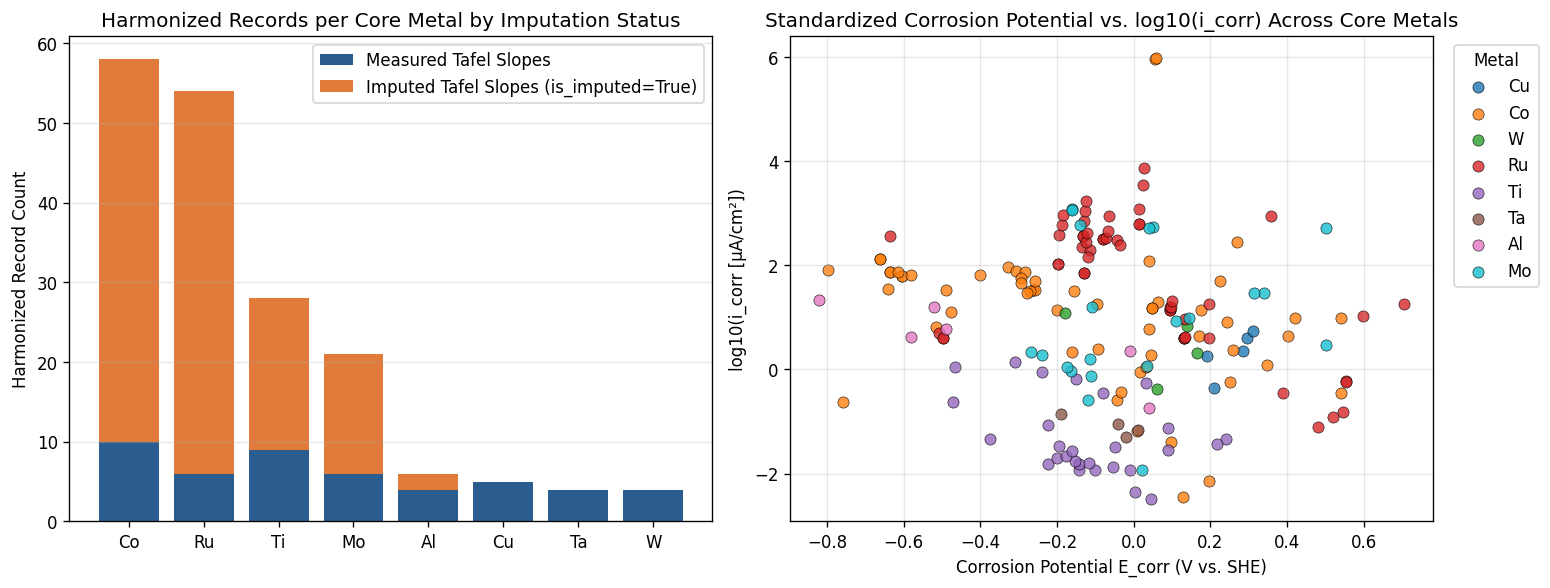

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

palette = ["#1f77b4", "#ff7f0e", "#2ca02c", "#d62728", "#9467bd", "#8c564b", "#e377c2", "#17becf"]
metals_ordered = list(metal_summary["metal"])
x_pos = np.arange(len(metals_ordered))

axes[0].bar(x_pos, metal_summary["measured_slopes"], label="Measured Tafel Slopes", color="#2b5c8f")
axes[0].bar(
    x_pos,
    metal_summary["imputed_slopes"],
    bottom=metal_summary["measured_slopes"],
    label="Imputed Tafel Slopes (is_imputed=True)",
    color="#e07b39",
)
axes[0].set_xticks(x_pos)
axes[0].set_xticklabels(metals_ordered)
axes[0].set_ylabel("Harmonized Record Count")
axes[0].set_title("Harmonized Records per Core Metal by Imputation Status")
axes[0].legend(loc="upper right")
axes[0].grid(axis="y", alpha=0.3)

for idx, metal in enumerate(CORE_METALS):
    sub = echem[echem["metal"] == metal]
    axes[1].scatter(
        sub["Ecorr_V_SHE"],
        sub["log10_icorr_uA_cm2"],
        label=metal,
        color=palette[idx % len(palette)],
        alpha=0.8,
        s=45,
        edgecolors="black",
        linewidths=0.4,
    )

axes[1].set_xlabel("Corrosion Potential E_corr (V vs. SHE)")
axes[1].set_ylabel("log10(i_corr [µA/cm²])")
axes[1].set_title("Standardized Corrosion Potential vs. log10(i_corr) Across Core Metals")
axes[1].legend(title="Metal", bbox_to_anchor=(1.02, 1), loc="upper left")
axes[1].grid(True, alpha=0.3)

plt.tight_layout()

## 4. Per-Solution Galvanic Series Ranking

Within each **Solution**, metals are ranked monotonically by $E_{\text{corr}}$ ($\text{V vs. SHE}$) from most active (`galvanic_rank = 1`, net anode) to most noble (`galvanic_rank = N`, net cathode).

In [5]:
gs_acidic = db.galvanic_series[db.galvanic_series["solution_id"] == "SOL_SEED_H2O2_CITRIC_PH4"]
print(
    gs_acidic[
        ["galvanic_rank", "metal", "Ecorr_V_SHE", "icorr_uA_cm2", "beta_a_mV_dec", "beta_c_mV_dec", "relative_nobility"]
    ].to_string(index=False)
)

 galvanic_rank metal  Ecorr_V_SHE  icorr_uA_cm2  beta_a_mV_dec  beta_c_mV_dec     relative_nobility
             1    Al       -0.580          4.20           68.0          126.0  Most Active (Anodic)
             2    Ti       -0.150          0.65          115.0          150.0          Intermediate
             3    Co       -0.095         18.50           64.0          122.0          Intermediate
             4    Ta       -0.040          0.09          135.0          160.0          Intermediate
             5    Mo        0.110          8.40           74.0          130.0          Intermediate
             6     W        0.140          6.80           85.0          140.0          Intermediate
             7    Cu        0.290          3.20           60.0          121.0          Intermediate
             8    Ru        0.520          0.12           92.0          128.0 Most Noble (Cathodic)


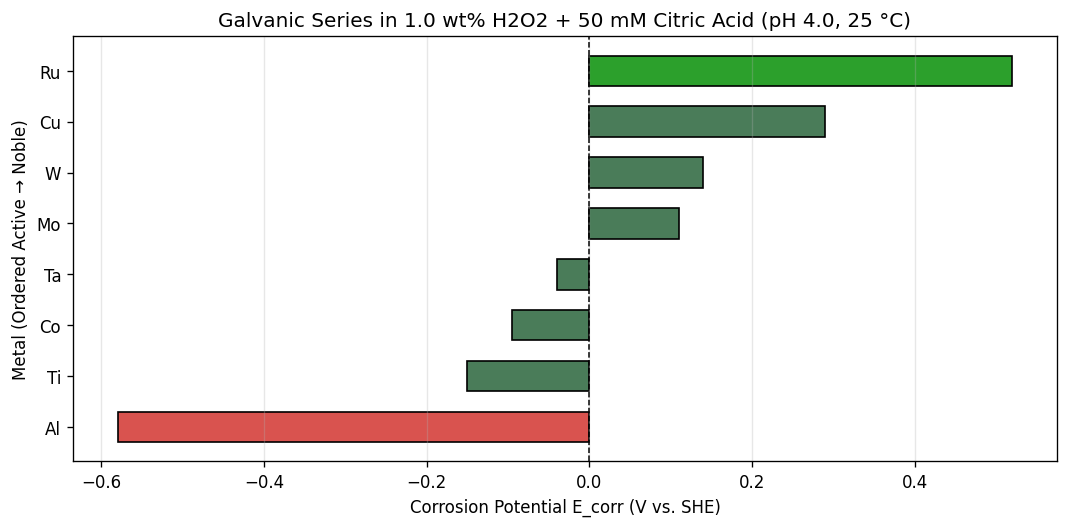

In [6]:
fig, ax = plt.subplots(figsize=(9, 4.5))
bar_colors = ["#d9534f" if r == 1 else ("#2ca02c" if r == len(gs_acidic) else "#4a7c59") for r in gs_acidic["galvanic_rank"]]
ax.barh(gs_acidic["metal"], gs_acidic["Ecorr_V_SHE"], color=bar_colors, edgecolor="black", height=0.6)
ax.axvline(0.0, color="black", linestyle="--", linewidth=0.9, label="0.0 V vs. SHE")
ax.set_xlabel("Corrosion Potential E_corr (V vs. SHE)")
ax.set_ylabel("Metal (Ordered Active → Noble)")
ax.set_title("Galvanic Series in 1.0 wt% H2O2 + 50 mM Citric Acid (pH 4.0, 25 °C)")
ax.grid(axis="x", alpha=0.3)
plt.tight_layout()

## 5. Exact & Nearest-Neighbor Exposure Condition Lookup and Data Dictionary

The lookup engine filters by exact **Metal** and oxidizer category, then ranks candidate records by Min-Max normalized Euclidean distance across `pH`, `oxidizer_concentration`, and `temperature_C`.

In [7]:
exact_match = db.lookup_exposure_condition(
    "Cu", pH=4.0, oxidizer_type="H2O2", oxidizer_concentration=1.0, temperature_C=25.0
)
approx_match = db.lookup_exposure_condition(
    "Cu", pH=4.4, oxidizer_type="H2O2", oxidizer_concentration=1.2, temperature_C=28.0
)

print("Exact lookup:", exact_match.mismatch_summary)
print("  Parameters:", (exact_match.Ecorr_V_SHE, exact_match.icorr_uA_cm2, exact_match.beta_a_mV_dec, exact_match.beta_c_mV_dec))
print("Approximate lookup:", approx_match.mismatch_summary)
print("  Condition differences:", approx_match.condition_differences)
print("\nData Dictionary sample (core electrochemical attributes):")
print(
    db.data_dictionary[db.data_dictionary["table_name"] == "electrochemical_database"][
        ["column_name", "attribute_role", "unit", "non_null_count", "description"]
    ]
    .head(12)
    .to_string(index=False)
)

Exact lookup: Exact match on Cu in H2O2 (pH=4.00, conc=1, T=25.0 °C).
  Parameters: (0.285, 2.3, 58.0, 118.0)
Approximate lookup: Nearest-neighbor match (ΔpH = -0.40 (matched 4.00 vs query 4.40); Δoxidizer_concentration = -0.2 (matched 1 vs query 1.2); Δtemperature_C = -3.0 °C (matched 25.0 vs query 28.0 °C); distance=0.1690).
  Condition differences: {'pH': -0.40000000000000036, 'oxidizer_concentration': -0.19999999999999996, 'temperature_C': -3.0}

Data Dictionary sample (core electrochemical attributes):
               column_name attribute_role          unit  non_null_count                                                                    description
                 record_id     identifier dimensionless             180                          Unique electrochemical measurement record identifier.
               material_id     identifier dimensionless             180                                    Canonical Metal identifier matching symbol.
               solution_id     ide

### Data Analysis Key Findings

- **Unified Multi-Metal Coverage**: Harmonizing `data/raw/` with the built-in benchmark seed yields **180 valid electrochemical records** across all **8 core semiconductor metals** (`Co`: 58, `Ru`: 54, `Ti`: 28, `Mo`: 21, `Al`: 6, `Cu`: 5, `W`: 4, `Ta`: 4), along with **8 deduplicated material property rows**, **149 deduplicated solution formulations**, and **71 per-solution Galvanic Series rankings**.
- **Reference Electrode & Unit Standardization**: Every record's Corrosion Potential ($E_{\text{corr}}$) is standardized to $\text{V vs. SHE}$ (applying $+0.197\text{ V}$ for $\text{Ag/AgCl}$, $+0.241\text{ V}$ for $\text{SCE}$, $+0.640\text{ V}$ for $\text{MSE}$, and $-0.05916 \times \text{pH}$ for $\text{RHE}$), while Corrosion Current Densities ($i_{\text{corr}}$) span $0.01$ to $>1000\text{ }\mu\text{A/cm}^2$ and all Tafel slopes ($\beta_a, \beta_c$) are strictly positive $\text{mV/dec}$.
- **Transparent Tafel Slope Imputation**: Out of 180 records with complete $(E_{\text{corr}}, i_{\text{corr}})$ pairs, **48 records** retain directly measured Tafel slopes (`is_imputed = False`) and **132 records** receive same-metal/same-oxidizer median (or $60 / 120\text{ mV/dec}$ fallback) imputation (`is_imputed = True`) with an automatic `-0.15` decrement to `quality_score`.
- **Galvanic Series Ordering**: In acidic peroxide cleaning ($1.0\text{ wt\% H}_2\text{O}_2 + 50\text{ mM citric acid}$, $\text{pH } 4.0$), the monotonic Galvanic Series orders the eight metals from most active to most noble as $\text{Al } (-0.580\text{ V}) < \text{Ti } (-0.150\text{ V}) < \text{Co } (-0.095\text{ V}) < \text{Ta } (-0.040\text{ V}) < \text{Mo } (0.110\text{ V}) < \text{W } (0.140\text{ V}) < \text{Cu } (0.290\text{ V}) < \text{Ru } (0.520\text{ V vs. SHE})$.

### Insights or Next Steps

- **High Galvanic Driving Force Between Interconnect & Liner Metals**: The $>0.38\text{ V}$ potential gap between $\text{Co}$ ($-0.095\text{ V vs. SHE}$) and $\text{Cu}$ ($0.290\text{ V}$) or $\text{Ru}$ ($0.520\text{ V}$) in acidic peroxide solutions indicates severe anodic acceleration risk for cobalt liners when electrically coupled to copper or ruthenium during wet cleaning.
- **Proceed to Phase 1 Physics & Phase 2 Hybrid ML**: Use the harmonized $(E_{\text{corr}}, i_{\text{corr}}, \beta_a, \beta_c)$ parameters retrieved via `lookup_exposure_condition` to drive the four-parameter Wagner-Traud Polarization Curve solver, Faraday Corrosion Rate converter, and log-space ML uncertainty predictor.